# 05 · Uncertainty after 5, 10 and 20 nominal periods
Forecast local covariance with continuing scheduled LSO measurements, using one initial prior and no orbit resets.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "configs" / "baseline.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "configs" / "baseline.json").exists():
    raise RuntimeError("Open this notebook from the project root or notebooks directory")
sys.path.insert(0, str(ROOT / "src"))
from halo_tracking.study import load_config
cfg = load_config(ROOT / "configs" / "baseline.json")


## Interpretation
These are zero-innovation covariance forecasts, not Monte Carlo errors. The supplied rounded initial state is propagated continuously without stationkeeping or periodic tiling. It departs the lunar halo region by about 10 nominal periods. Long-span values therefore describe that continued CR3BP trajectory, not a maintained periodic halo. The existing Monte Carlo inconsistency also limits the interpretation of these local covariance predictions.

In [2]:
from halo_tracking.horizons import forecast_horizons, save_horizon_forecast
periods = [1, 5, 10, 20]
forecast = forecast_horizons(cfg, periods=periods)
save_horizon_forecast(forecast, ROOT / "results/horizons")

/workspace/scratch/678b6a3ef004/Halo_Orbit_Tracking/src/halo_tracking/horizons.py:25: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  result = make_truth(config, extra_times=checkpoints)


## Exact checkpoint values
RSS σ is the square root of the covariance-block trace. The CSV/JSON also contains per-axis position, velocity and acceleration standard deviations. Checkpoints do not add observations off the configured measurement cadence.

In [3]:
from IPython.display import HTML, display
columns = [("periods", "Periods"), ("days", "Days"), ("measurement_case", "Measurements"), ("position_rss_sigma_km", "Position RSS σ (km)"), ("velocity_rss_sigma_m_s", "Velocity RSS σ (m/s)"), ("acceleration_rss_sigma_m_s2", "Acceleration RSS σ (m/s²)"), ("moon_distance_km", "Moon distance (km)")]
headers = "".join("<th>" + label + "</th>" for _, label in columns)
rows = []
for row in sorted(forecast["horizon_rows"], key=lambda r: (r["periods"], r["measurement_case"])):
    values = [f"{row[key]:.6g}" if isinstance(row[key], (int, float)) else row[key] for key, _ in columns]
    rows.append("<tr>" + "".join("<td>" + value + "</td>" for value in values) + "</tr>")
display(HTML("<table><tr>" + headers + "</tr>" + "".join(rows) + "</table>"))

Periods,Days,Measurements,Position RSS σ (km),Velocity RSS σ (m/s),Acceleration RSS σ (m/s²),Moon distance (km)
1,8.06485,angles,1.14816,0.00553488,2.44469e-08,76205.9
1,8.06485,angles_rates,1.1481,0.00553469,2.4446e-08,76205.9
5,40.3243,angles,0.031237,9.70182e-05,4.96606e-10,78150.8
5,40.3243,angles_rates,0.0306233,9.5134e-05,4.86994e-10,78150.8
10,80.6485,angles,0.17058,9.71533e-05,4.04098e-10,906033
10,80.6485,angles_rates,0.165084,9.41677e-05,3.91358e-10,906033
20,161.297,angles,0.0340416,8.78103e-05,1.05404e-10,873866
20,161.297,angles_rates,0.0338864,8.75265e-05,1.04913e-10,873866


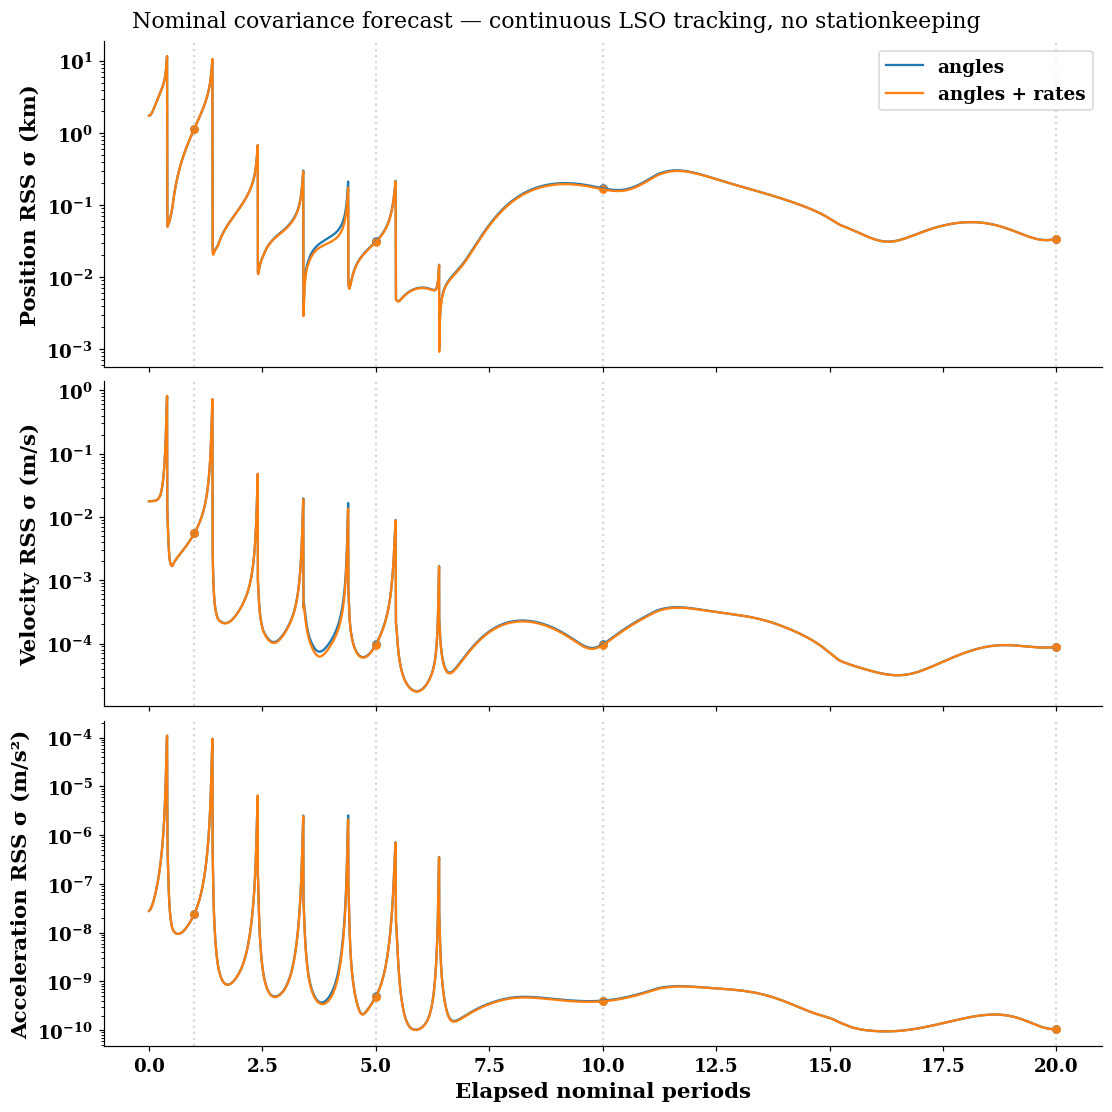

In [4]:
from halo_tracking.plotting import horizon_comparison, export
fig = horizon_comparison(forecast)
export(fig, ROOT / "results/horizons/horizon_uncertainty.png")

## Continued trajectory
This figure checks the geometry behind the covariance forecast. Its physical axis scales are equal. Axis-label clearance updates with figure size, camera orientation and export resolution.

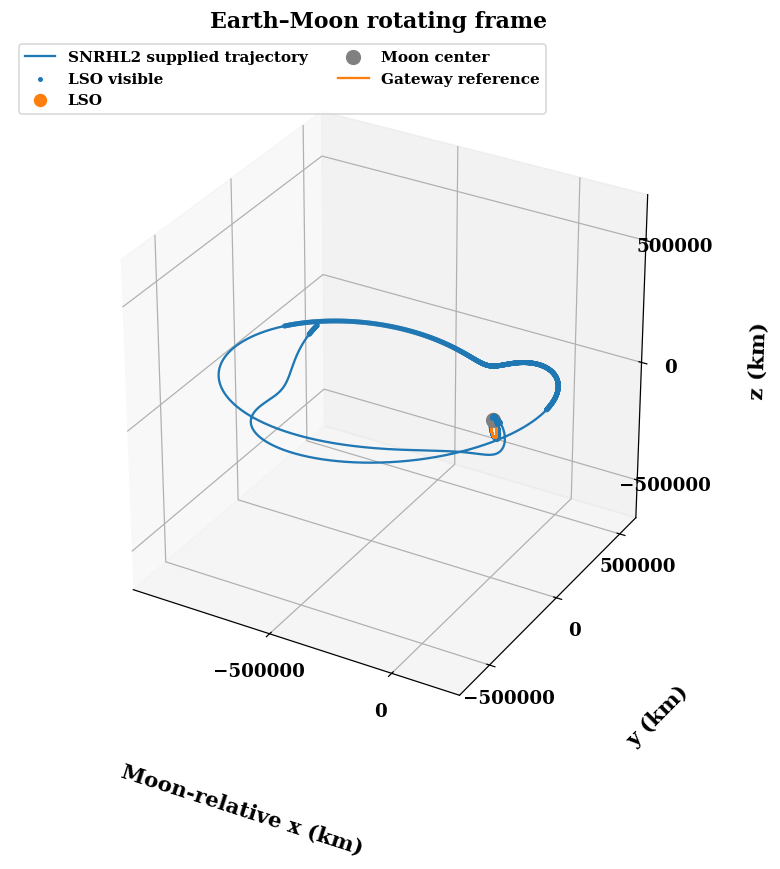

In [5]:
from halo_tracking.plotting import geometry
fig_geometry = geometry(forecast)
export(fig_geometry, ROOT / "results/horizons/continued_trajectory.png")